<a href="https://colab.research.google.com/github/PawanSingh130901/Pawan-Singh/blob/main/eda23bds0041.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

# 1. Loading the dataset
url = 'https://raw.githubusercontent.com/salemprakash/EDA/main/Data/GSS7402.csv'
df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset Shape: (9120, 11)


,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
0,1,0,25,14,2002,1,NaN,cauc,no,no,no
1,2,1,30,13,2002,4,19.0,cauc,yes,no,no
2,3,1,55,2,2002,1,27.0,cauc,no,no,yes
3,4,2,57,16,2002,1,22.0,cauc,no,no,no
4,5,2,71,12,2002,6,29.0,cauc,yes,no,no


In [3]:
print("\n--- Data Types and Non-Null Counts ---")
df.info()

print("\n--- Summary Statistics (Numerical) ---")
display(df.describe())

print("\n--- Summary Statistics (Categorical) ---")
display(df.describe(include=['object', 'category']))


--- Data Types and Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9120 entries, 0 to 9119
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   rownames       9120 non-null   int64  
 1   kids           9120 non-null   int64  
 2   age            9120 non-null   int64  
 3   education      9120 non-null   int64  
 4   year           9120 non-null   int64  
 5   siblings       9120 non-null   int64  
 6   agefirstbirth  3312 non-null   float64
 7   ethnicity      9120 non-null   object 
 8   city16         9120 non-null   object 
 9   lowincome16    9120 non-null   object 
 10  immigrant      9120 non-null   object 
dtypes: float64(1), int64(6), object(4)
memory usage: 783.9+ KB

--- Summary Statistics (Numerical) ---


,rownames,kids,age,education,year,siblings,agefirstbirth
count,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,3312.000000
mean,4560.500000,2.076096,46.082018,12.635088,1990.288596,4.050658,22.630737
std,2632.861561,1.805099,17.923889,2.955190,9.096915,3.246137,4.859220
min,1.000000,0.000000,18.000000,0.000000,1974.000000,0.000000,9.000000
25%,2280.750000,1.000000,31.000000,12.000000,1982.000000,2.000000,19.000000
50%,4560.500000,2.000000,43.000000,12.000000,1994.000000,3.000000,22.000000
75%,6840.250000,3.000000,59.000000,14.000000,1998.000000,6.000000,25.000000
max,9120.000000,8.000000,89.000000,20.000000,2002.000000,35.000000,42.000000



--- Summary Statistics (Categorical) ---


,ethnicity,city16,lowincome16,immigrant
count,9120,9120,9120,9120
unique,2,2,2,2
top,cauc,no,no,no
freq,7335,5246,7182,8122


In [4]:
print("Missing values before handling:\n", df.isnull().sum())

# Separate columns by data type
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns

# Strategy: Fill numerical missing values with the median
for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)

# Strategy: Fill categorical missing values with the mode (most frequent value)
for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

print("\nMissing values after handling:\n", df.isnull().sum())

Missing values before handling:
 rownames            0
kids                0
age                 0
education           0
year                0
siblings            0
agefirstbirth    5808
ethnicity           0
city16              0
lowincome16         0
immigrant           0
dtype: int64

Missing values after handling:
 rownames         0
kids             0
age              0
education        0
year             0
siblings         0
agefirstbirth    0
ethnicity        0
city16           0
lowincome16      0
immigrant        0
dtype: int64


In [6]:
# Check for and drop exact duplicate rows
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows found: {duplicates}")

if duplicates > 0:
    df.drop_duplicates(inplace=True)
    print("Duplicates removed. New shape:", df.shape)

Number of duplicate rows found: 0


In [7]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in cat_cols:
    # We create a new encoded column to preserve the original for certain visualizations
    df[col + '_encoded'] = le.fit_transform(df[col].astype(str))

print("Data Transformation complete. Updated columns:")
display(df.head())

Data Transformation complete. Updated columns:


,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant,ethnicity_encoded,city16_encoded,lowincome16_encoded,immigrant_encoded
0,1,0,25,14,2002,1,22.0,cauc,no,no,no,0,0,0,0
1,2,1,30,13,2002,4,19.0,cauc,yes,no,no,0,1,0,0
2,3,1,55,2,2002,1,27.0,cauc,no,no,yes,0,0,0,1
3,4,2,57,16,2002,1,22.0,cauc,no,no,no,0,0,0,0
4,5,2,71,12,2002,6,29.0,cauc,yes,no,no,0,1,0,0


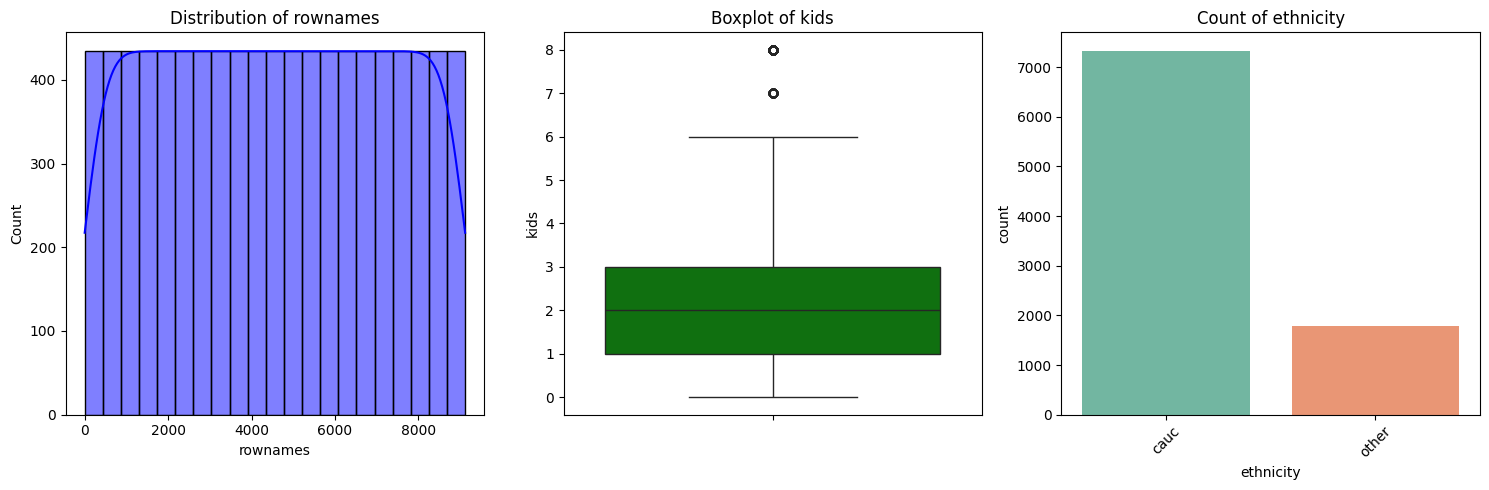

In [8]:
# Visualizing single variables independently
plt.figure(figsize=(15, 5))

# Plot 1: Histogram of the first numerical column
plt.subplot(1, 3, 1)
sns.histplot(df[num_cols[0]], kde=True, color='blue')
plt.title(f'Distribution of {num_cols[0]}')

# Plot 2: Boxplot of the second numerical column (if available, else reuse first)
col2 = num_cols[1] if len(num_cols) > 1 else num_cols[0]
plt.subplot(1, 3, 2)
sns.boxplot(y=df[col2], color='green')
plt.title(f'Boxplot of {col2}')

# Plot 3: Countplot of the first categorical column
plt.subplot(1, 3, 3)
sns.countplot(x=df[cat_cols[0]], palette='Set2')
plt.title(f'Count of {cat_cols[0]}')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

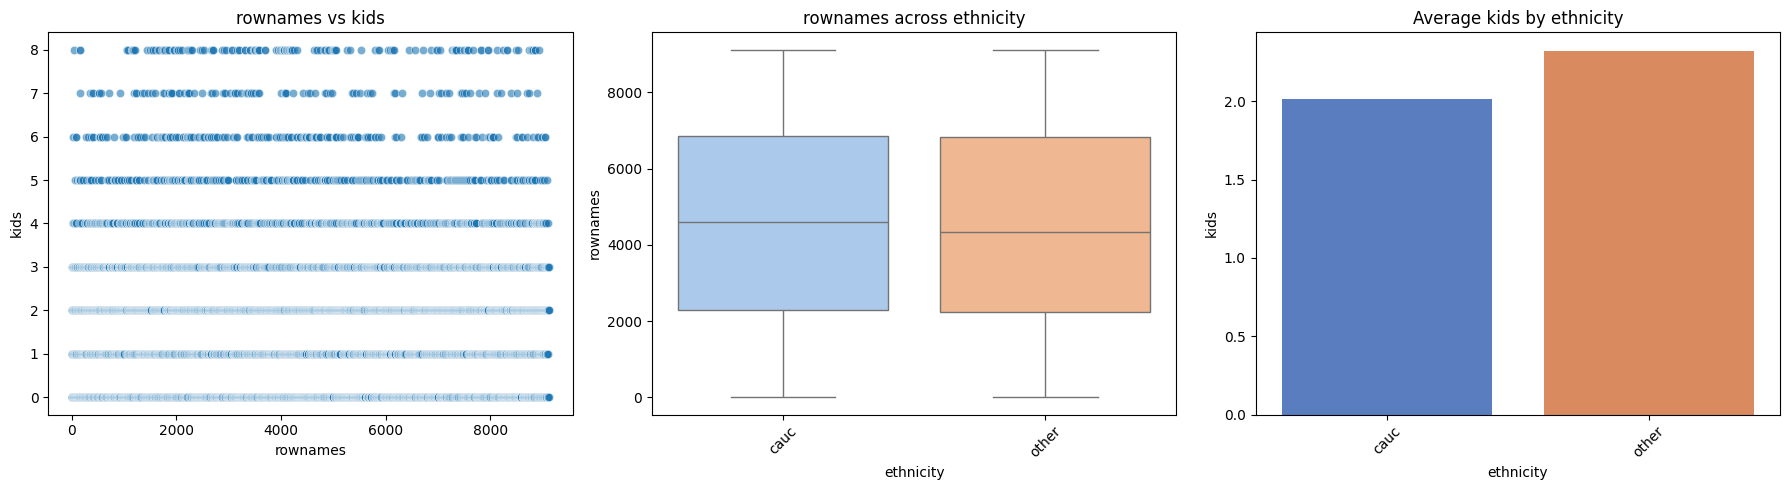

In [9]:
# Visualizing relationships between two variables
plt.figure(figsize=(18, 5))

# Plot 1: Scatter plot between first two numerical columns
plt.subplot(1, 3, 1)
sns.scatterplot(x=df[num_cols[0]], y=df[num_cols[1]], alpha=0.6)
plt.title(f'{num_cols[0]} vs {num_cols[1]}')

# Plot 2: Boxplot comparing a categorical and a numerical variable
plt.subplot(1, 3, 2)
sns.boxplot(x=df[cat_cols[0]], y=df[num_cols[0]], palette='pastel')
plt.title(f'{num_cols[0]} across {cat_cols[0]}')
plt.xticks(rotation=45)

# Plot 3: Barplot comparing categorical with another numerical variable
plt.subplot(1, 3, 3)
sns.barplot(x=df[cat_cols[0]], y=df[num_cols[1]], palette='muted', errorbar=None)
plt.title(f'Average {num_cols[1]} by {cat_cols[0]}')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

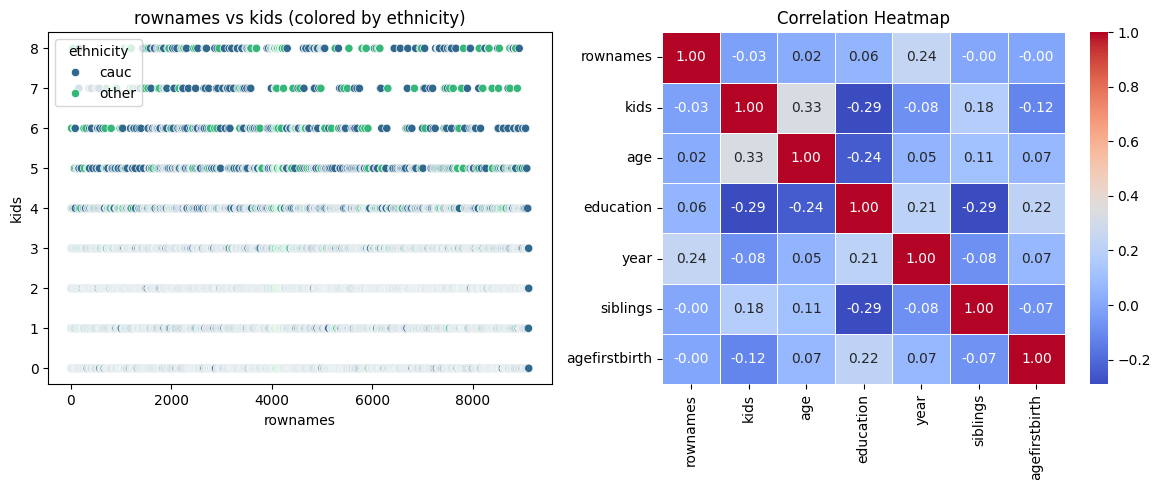


Plot 3: Pairplot (subset of numerical variables + hue)


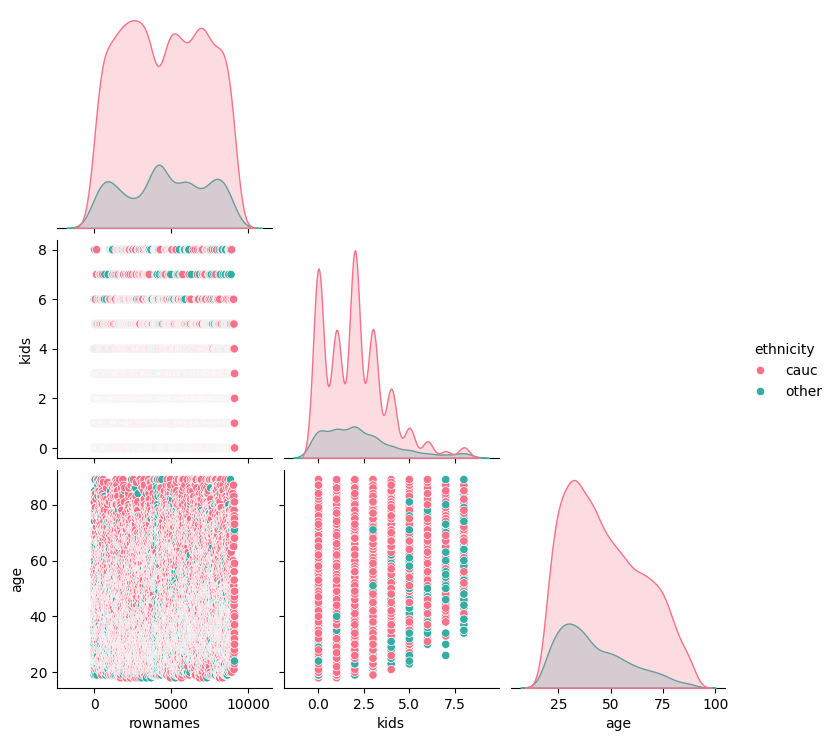

In [10]:
# Visualizing relationships between three or more variables
plt.figure(figsize=(18, 5))

# Plot 1: Scatter plot with a hue (3 variables: 2 numerical, 1 categorical)
plt.subplot(1, 3, 1)
sns.scatterplot(x=df[num_cols[0]], y=df[num_cols[1]], hue=df[cat_cols[0]], palette='viridis')
plt.title(f'{num_cols[0]} vs {num_cols[1]} (colored by {cat_cols[0]})')

# Plot 2: Correlation Heatmap (All numerical variables)
plt.subplot(1, 3, 2)
correlation_matrix = df[num_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')

# Plot 3: Pairplot (Selecting a subset to avoid massive rendering times)
# Note: Pairplot creates its own figure, so we call it separately
plt.tight_layout()
plt.show()

print("\nPlot 3: Pairplot (subset of numerical variables + hue)")
# Selecting first 3 numerical cols + 1 categorical for the pairplot to keep it readable
cols_to_plot = list(num_cols[:3]) + [cat_cols[0]]
sns.pairplot(df[cols_to_plot], hue=cat_cols[0], palette='husl', corner=True)
plt.show()